# Prompt complexity classifier

Train a multilingual CPU baseline using [WildChat tagged](https://huggingface.co/datasets/sh0416/wildchat-1m-tagged).

**Easy: 1–3 · Medium: 4–7 · Hard: 8–10**

Run cells in order from this project folder. The full download needs several GB of disk space. Prompt cleaning uses RAM; training features are processed in batches.

In [1]:
# Install once in the selected kernel. Restart the kernel afterward if needed.
%pip install -r requirements.txt

/home/basil/Documents/github/ibmhack26/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from complexity import CLASSES, prepare_data, split_data, train_model, evaluate, save_model, classify_prompt

ROOT = Path.cwd()
assert (ROOT / 'complexity.py').exists(), 'Run from the project directory.'

C:\Users\ghile\GitRepos\EcoPrompt\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Download and clean

Download the full dataset at a pinned revision. Use the first nonempty user message, assuming its conversation-level complexity label applies to that opening prompt. Exclude invalid scores and empty prompts. Keep all languages. Deduplicate NFKC-normalized, case-folded, whitespace-collapsed prompts; remove all conflicting-label groups. Only prompt text becomes a feature.

Source license: ODC-BY. Retain attribution to the linked dataset when sharing derived data.

In [2]:
frame, manifest = prepare_data(ROOT)
display(pd.Series(manifest['cleaning'], name='Count').to_frame())
display(frame.label.value_counts().reindex(CLASSES).rename('Count').to_frame())
display(frame.language.value_counts().head(20).rename('Count').to_frame())

Downloading/loading full dataset at revision c779cc987d9c546fbb822e3b962bf90b133f11ec


Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

C:\Users\ghile\GitRepos\EcoPrompt\backend\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ghile\GitRepos\EcoPrompt\backend\data\hf_home\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


C:\Users\ghile\GitRepos\EcoPrompt\backend\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ghile\GitRepos\EcoPrompt\backend\data\hf_home\hub\datasets--sh0416--wildchat-1m-tagged. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Fetching 15 files:   7%|▋         | 1/15 [00:00<00:04,  2.94it/s]

Fetching 15 files:  13%|█▎        | 2/15 [00:07<00:58,  4.49s/it]

...

Cleaned 800,000 source rows


{
  "source_rows": 837989,
  "duplicate_rows_removed": 75522,
  "missing_prompt_rows": 3630,
  "invalid_score_rows": 34551,
  "conflicting_rows": 58742,
  "conflicting_prompt_groups": 8215,
  "retained_rows": 665544
}


,Count
source_rows,837989
duplicate_rows_removed,75522
missing_prompt_rows,3630
invalid_score_rows,34551
conflicting_rows,58742
conflicting_prompt_groups,8215
retained_rows,665544


,Count
label,
easy,237381
medium,303207
hard,124956


,Count
language,
English,375173
Chinese,103827
Russian,74368
French,23780
Spanish,17158
Arabic,10199
Portuguese,9081
German,5422
Turkish,4234


## Split and train

Stratify 80/10/10 with seed 42. Train character 3–5-gram hashing features with an averaged SGD logistic classifier and training-derived class weights. Train three regularization settings for five epochs and select by validation macro-F1. Keep test examples out of model selection.

In [3]:
train, validation, test = split_data(frame)
parts = [('train', train), ('validation', validation), ('test', test)]
display(pd.DataFrame({name: part.label.value_counts().reindex(CLASSES, fill_value=0) for name, part in parts}))
pd.concat([part[['prompt_hash']].assign(split=name) for name, part in parts]).to_parquet(ROOT / 'data' / 'splits.parquet', index=False)
model, validation_results = train_model(train, validation, cache_dir=ROOT / 'data' / 'features')
display(pd.DataFrame(validation_results))

,train,validation,test
label,,,
easy,189905,23738,23738
medium,242565,30321,30321
hard,99965,12495,12496


Epoch 1/5: 51,200/532,435 prompts


Epoch 1/5: 102,400/532,435 prompts


Epoch 1/5: 153,600/532,435 prompts


Epoch 1/5: 204,800/532,435 prompts


...

Epoch 5/5: 410,067/532,435 prompts


Epoch 5/5: 461,267/532,435 prompts


Epoch 5/5: 512,467/532,435 prompts


Finished training epoch 5/5


,alpha,validation_macro_f1
0,0.00001,0.666623
1,0.00010,0.638502
2,0.00100,0.610420


## Held-out evaluation

Macro-F1 gives equal weight to the three classes. Compare against always choosing the most common training class. Report language groups with at least 100 test examples. Performance measures agreement with dataset labels, not universal prompt difficulty.

,model,accuracy,macro_f1,label
0,Character classifier,0.649944,0.667267,NaN
1,Majority baseline,0.455578,0.208658,medium


,precision,recall,f1-score,support
easy,0.594053,0.689275,0.638131,23738.000000
medium,0.647497,0.604532,0.625277,30321.000000
hard,0.800243,0.685419,0.738394,12496.000000
accuracy,0.649944,0.649944,0.649944,0.649944
macro avg,0.680598,0.659742,0.667267,66555.000000
weighted avg,0.657114,0.649944,0.651100,66555.000000


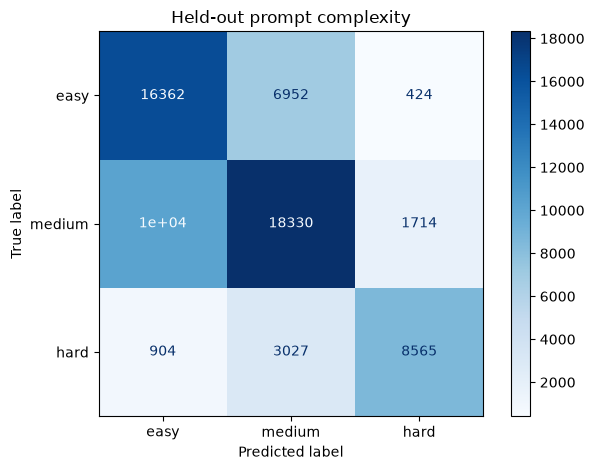

,count,accuracy,macro_f1
English,37553,0.683887,0.688911
Chinese,10356,0.563828,0.556676
Russian,7465,0.616343,0.467522
French,2361,0.660313,0.490719
Spanish,1704,0.607394,0.534194
Arabic,1049,0.656816,0.410364
Portuguese,928,0.620690,0.478406
German,507,0.581854,0.468385
Italian,471,0.549894,0.369887
Vietnamese,385,0.662338,0.448995


In [4]:
metrics = evaluate(model, train, test)
display(pd.DataFrame([
    {'model': 'Character classifier', 'accuracy': metrics['accuracy'], 'macro_f1': metrics['macro_f1']},
    {'model': 'Majority baseline', **metrics['majority_baseline']},
]))
display(pd.DataFrame(metrics['classification_report']).T)
ConfusionMatrixDisplay(np.array(metrics['confusion_matrix']), display_labels=CLASSES).plot(cmap='Blues')
plt.title('Held-out prompt complexity')
plt.tight_layout()
plt.show()
language_results = pd.DataFrame.from_dict(metrics['by_language'], orient='index')
display(language_results.sort_values('count', ascending=False) if not language_results.empty else language_results)

In [5]:
metadata = {
    'dataset': manifest,
    'split_sizes': {name: len(part) for name, part in parts},
    'validation_candidates': validation_results,
    'selected_alpha': model.named_steps['classifier'].alpha,
    'epochs': 5, 'batch_size': 512, 'test_metrics': metrics,
    'shuffle_strategy': 'Seeded batch order and within-batch row order; disk-cached features',
    'label_assumption': 'Conversation complexity supervises the first nonempty user prompt.',
}
model_path = save_model(model, metadata, ROOT)
reloaded_model = joblib.load(model_path)
examples = ['Hello!', 'Explain photosynthesis.', '解释机器学习中的过拟合。', 'Design a distributed system.\nExplain its failure recovery strategy.']
assert np.array_equal(model.predict(examples), reloaded_model.predict(examples))
print(f'Saved model: {model_path}')
print(f'Saved metrics: {ROOT / "artifacts" / "metrics.json"}')

Saved model: C:\Users\ghile\GitRepos\EcoPrompt\backend\artifacts\complexity_model.joblib
Saved metrics: C:\Users\ghile\GitRepos\EcoPrompt\backend\artifacts\metrics.json


## Try a prompt

Edit the text below and rerun the cell. After restarting, run the imports cell and this cell to load the saved model without training. Any nonempty text is accepted; accuracy varies by language and topic. The result includes a class, score range, and model confidence.

In [6]:
prompt = 'Design a distributed banking transaction processing system capable of handling 100,000 transactions per second across three geographically separated data centres. The system must guarantee that no transaction is processed twice, maintain consistency during network partitions, and recover automatically from data-centre failures. Compare at least three architectural approaches, analyse their trade-offs using the CAP theorem, propose a fault-tolerant architecture, provide pseudocode for its transaction processing and recovery mechanisms, and mathematically justify how your design meets its reliability and performance requirements.'
classify_prompt(prompt, model_path=ROOT / 'artifacts' / 'complexity_model.joblib')

{'label': 'hard', 'score_range': '8-10', 'confidence': 0.46038171648979187}